# Stage 3: anisotropic face messages with curve geometry

Adapt `notebooks/06_Graph_Convnets/code04_dgl_solution.ipynb` and `code05_dgl_solution.ipynb`: feature-wise sigmoid gates, incoming-neighbour normalization, graph-size normalization, BatchNorm, ReLU and residual connections. Use the UV-Net EdgeCNN (6 channels: xyz and tangent) to encode curves. This is a course-style GatedGCN experiment; it does not reproduce UV-Net's NNConv or solid-level readout.

Both variants use **exactly two graph layers**, hence two-hop face message passing:

- `edge_mode="static"`: encode the edge grid once, and use the same edge state at both graph layers. Each layer learns its own gate `q_ij=C_l e_ij`.
- `edge_mode="updated"`: `q_ij=C_l e_ij+D_l h_i+E_l h_j` gates the current face message. Carry `e_ij + ReLU(BN(q_ij / sqrt(number_of_edges)))` from layer 1 to layer 2. The final edge carry is omitted because no later layer or edge loss consumes it.

The EdgeCNN is trained in **both** variants; static refers to the absence of graph-layer edge-state updates, not frozen encoder weights. No free embedding per edge ID is learned, so the model works on unseen solids. The updated variant adds endpoint-conditioned gates as well as recurrent edge state; this is an architectural progression, not an isolated test of recurrence alone.

`training_mode="joint"` fine-tunes the baseline FaceCNN; `"frozen"` caches its embeddings. There is no pre-trained EdgeCNN, so it is always learned from the face loss. Preserve the dataset's original directed edges and their matching curve grids, including parallel B-rep edges. Do not simplify or add edges: that would destroy curve alignment. Solids are batched with index offsets and never connected to each other. No pooling or shallow descriptors are included.

Reference: [Residual Gated Graph ConvNets](https://arxiv.org/abs/1711.07553) and [UV-Net curve encoder](https://github.com/AutodeskAILab/UV-Net/blob/main/uvnet/encoders.py).
Final prediction exports include ordered sample IDs, per-row sample indices and zero-based graph face indices. These are checked against annotation labels; STEP viewer face identity is a separate mapping.


In [1]:
import os
os.environ["DGLBACKEND"] = "pytorch"

import csv
import hashlib
import json
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from uvnet_project.checkpointing import seed_everything, save_training_checkpoint, load_training_checkpoint
from uvnet_project.face_cnn import FaceCNN
from uvnet_project.anisotropic import collate_face_edges, AnisotropicFaceClassifier
from uvnet_project.load_mfcad import DATA_DIR, _load_sample, _load_splits
from uvnet_project.evaluation import evaluate

## Reproducibility and resume

Fresh runs seed Python, NumPy and Torch CPU/CUDA. Each epoch exports weights and an atomic checkpoint with optimizer, AMP scaler, initial seed/RNG state, histories, baseline identity and all architecture settings. Resume at a completed epoch with the same input cache, dataset order, software and GPU; `num_epochs` is the total target. No per-epoch seed reset. Mid-epoch interruption restarts from the last completed checkpoint.

Use a fresh kernel for deterministic CUDA settings. Gate normalization and message reductions use float32; CNNs and the pointwise classifier use AMP on CUDA. No training is performed during notebook preparation.

## Settings and baseline FaceCNN

Run `edge_mode="static"`, then `"updated"`. Default `training_mode="joint"` fine-tunes the FaceCNN; frozen mode is optional. Both use the same baseline FaceCNN and seeded fresh EdgeCNN initialization. Two graph layers are fixed; graph width is configurable, default 64. The per-face MLP width comes from the baseline config. Results and comparisons contain baseline + anisotropic variants only. The official test split is not used. Matching run files are overwritten.

In [10]:
seed = 0
deterministic = True
# Set a completed anisotropic checkpoint to resume, then rerun preparation cells.
# resume_checkpoint = DATA_DIR.parent.parent / "results/anisotropic_static_joint_run_01/epoch_010/checkpoint.pt"
resume_checkpoint = None
seed_everything(seed, deterministic=deterministic)

project_dir = DATA_DIR.parent.parent
baseline_checkpoint = project_dir / "results/baseline_run_01/epoch_020/checkpoint.pt"
training_mode = "joint"  # "frozen" or "joint" (FaceCNN only; EdgeCNN always trains)
edge_mode = "updated"  # "static" or "updated"
num_graph_layers = 2  # fixed two-hop architecture
graph_dim = 64
edge_in_channels = 6  # xyz + tangent
num_epochs = 20
batch_size = 128  # solids per batch
learning_rate = 0.001
run_dir = project_dir / "results" / f"anisotropic_{edge_mode}_{training_mode}_run_01"
cache_dir = project_dir / "data/feature_cache"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if training_mode not in ("frozen", "joint") or edge_mode not in ("static", "updated"):
    raise ValueError("Choose frozen/joint FaceCNN and static/updated edge state.")
if num_graph_layers != 2:
    raise ValueError("This notebook fixes two graph layers for both variants.")
if min(num_epochs, batch_size) < 1:
    raise ValueError("Epoch count and batch size must be positive.")
if not baseline_checkpoint.is_file():
    raise FileNotFoundError(f"Copy the completed baseline checkpoint here first: {baseline_checkpoint}")
checkpoint = torch.load(baseline_checkpoint, map_location="cpu", weights_only=True)
config = checkpoint["config"]
embedding_dim, hidden_dim = config["embedding_dim"], config["hidden_dim"]
num_classes, in_channels = config["num_classes"], config["in_channels"]
baseline_hash = hashlib.sha256(baseline_checkpoint.read_bytes()).hexdigest()
cnn_state = {key.removeprefix("0."): value for key, value in checkpoint["model_state_dict"].items()
             if key.startswith("0.")}
face_cnn = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
face_cnn.load_state_dict(cnn_state, strict=True)
face_cnn.requires_grad_(False)
face_cnn = face_cnn.to(device).eval()
print("Device:", device, "Mode:", training_mode, "Edge state:", edge_mode)

Device: cuda Mode: joint Edge state: updated


## Cache aligned face and curve inputs

Frozen mode caches baseline face embeddings; joint mode caches raw face grids. Both cache raw curve grids so the EdgeCNN remains trainable. Preserve original DGL edge-ID order exactly. Edges and edge grids cannot be sorted, removed or duplicated independently. The same mode-specific cache serves both static/updated variants. Metadata records baseline hash, split IDs and edge policy; retain caches for resume. Delete caches or increment the version if source data changes.

In [11]:
def metadata_key(metadata):
    return hashlib.sha256(json.dumps(metadata, sort_keys=True).encode()).hexdigest()[:16]


@torch.no_grad()
def prepare_inputs(split, encode_batch_size=128):
    sample_ids = _load_splits()[split]
    metadata = dict(cache_version=1, baseline_hash=baseline_hash, training_mode=training_mode,
                    sample_ids=sample_ids, embedding_dim=embedding_dim, in_channels=in_channels,
                    edge_policy="original_dgl_edge_id_order", edge_in_channels=edge_in_channels)
    path = cache_dir / f"anisotropic_inputs_{split}_{metadata_key(metadata)}.pt"
    if path.is_file():
        cached = torch.load(path, map_location="cpu", weights_only=True)
        if cached["metadata"] != metadata:
            raise ValueError("anisotropic input-cache metadata mismatch.")
        print("Using input cache:", path)
        return cached["samples"], sample_ids
    if resume_checkpoint is not None:
        raise FileNotFoundError(f"Retain the original anisotropic input cache for resume: {path}")
    face_cnn.eval()
    samples = []
    for start in tqdm(range(0, len(sample_ids), encode_batch_size), desc=f"Cache anisotropic inputs {split}"):
        solids = [_load_sample(sample_id) for sample_id in sample_ids[start:start + encode_batch_size]]
        embeddings = None
        if training_mode == "frozen":
            sizes = [solid["graph"].num_nodes() for solid in solids]
            grids = torch.cat([solid["graph"].ndata["x"] for solid in solids])
            grids = grids.permute(0, 3, 1, 2).contiguous().float().to(device)
            embeddings = face_cnn(grids).cpu().split(sizes)
        for offset, solid in enumerate(solids):
            graph = solid["graph"]
            edge_index = torch.stack(graph.edges(order="eid")).long()
            edge_grids = graph.edata["x"].permute(0, 2, 1).contiguous().float()
            if edge_grids.shape[1] != edge_in_channels:
                raise ValueError("Expected xyz and tangent channels in curve grids.")
            labels = torch.tensor([face["segment"]["index"] for face in solid["faces"]], dtype=torch.long)
            geometry = (embeddings[offset] if training_mode == "frozen" else
                        solid["graph"].ndata["x"].permute(0, 3, 1, 2).contiguous().float())
            samples.append((geometry, edge_grids, edge_index, labels))
    cache_dir.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(".pt.tmp")
    torch.save(dict(metadata=metadata, samples=samples), temporary)
    os.replace(temporary, path)
    return samples, sample_ids


train_samples, train_ids = prepare_inputs("train")
validation_samples, validation_ids = prepare_inputs("validation")

Using input cache: /home/yongjun23/project/data/feature_cache/anisotropic_inputs_train_5f9914fe23eccf3c.pt
Using input cache: /home/yongjun23/project/data/feature_cache/anisotropic_inputs_validation_e2aa747ab427d80e.pt


## Build the two-layer edge-gated model

`FaceCNN -> face projection (64D)` and `EdgeCNN -> edge features (64D)` feed two residual gated graph layers, then a pointwise `Linear -> ReLU -> Linear` classifier produces 16 logits per face. No whole-solid readout is used.

For incoming directed edges j→i, compute `gate=sigmoid(q_ij)` and `m_i=sum(gate * B h_j) / clamp(sum(gate), min=1e-6)`, independently per feature channel. Then `h_i_next=h_i+ReLU(BN((A h_i+m_i)/sqrt(number_of_faces_in_solid)))`. For isolated faces the neighbour sum is zero; the self transform remains. Updated edges use the tutorial's q and residual state update described above. Static edges use `C e` only.

The implementation uses plain Torch indexing and destination sums, corresponding to the tutorial's `message_func` and `reduce_func`. CUDA checks verify deterministic gradients. Batch normalization follows the tutorial and shares training statistics across batch items; it does not create graph edges between solids. Node/edge widths remain constant for residual additions.

In [12]:
def build_model():
    head = AnisotropicFaceClassifier(embedding_dim, graph_dim, hidden_dim, edge_mode,
                                     num_classes, edge_in_channels)
    if training_mode == "joint":
        # Keep initialization of classifier/shuffling identical between modes.
        with torch.random.fork_rng(devices=[]):
            encoder = FaceCNN(embedding_dim=embedding_dim, in_channels=in_channels)
        encoder.load_state_dict(cnn_state, strict=True)
        encoder.requires_grad_(True)
        head.face_cnn = encoder
    return head.to(device)


seed_everything(seed, deterministic=deterministic)
model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

AnisotropicFaceClassifier(
  (edge_cnn): EdgeCNN(
    (conv1): Sequential(
      (0): Conv1d(6, 64, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv2): Sequential(
      (0): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (conv3): Sequential(
      (0): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
      (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.01)
    )
    (pool): AdaptiveAvgPool1d(output_size=1)
    (fc): Sequential(
      (0): Linear(in_features=256, out_features=64, bias=False)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_run

## Batch independent solids and verify aligned inputs

Concatenate faces and curves and offset each solid's edge indices. `batch_size` counts solids. Each curve grid still matches the corresponding edge index column. Graph-size normalization is computed separately per solid, as in the tutorial. Check logits before training.

In [13]:
loader_options = dict(batch_size=batch_size, collate_fn=collate_face_edges,
                      num_workers=0, pin_memory=device.type == "cuda")
train_loader = DataLoader(train_samples, shuffle=True, **loader_options)
train_evaluation_loader = DataLoader(train_samples, shuffle=False, **loader_options)
validation_loader = DataLoader(validation_samples, shuffle=False, **loader_options)
inputs, labels = next(iter(validation_loader))
model.eval()
with torch.no_grad():
    logits = model(inputs.to(device))
assert logits.shape == (len(labels), num_classes)
assert torch.isfinite(logits).all()
print("Logits:", tuple(logits.shape), "Edges:", inputs.edge_index.shape[1])

Logits: (2852, 16) Edges: 15194


## Train the chosen anisotropic variant — run when ready

Log batch training loss and epoch training/validation loss and accuracy. Save resumable weights/checkpoints after every epoch; export prediction softmax only at the final epoch. The EdgeCNN always trains; joint mode also trains the FaceCNN. Loss plotting runs after training finishes. Final cached predictions give evaluation-mode metrics for both splits; training-loop metrics include updates and BatchNorm training behaviour.

In [14]:
seed_everything(seed, deterministic=deterministic)
if resume_checkpoint is None:
    model = build_model()
use_amp = device.type == "cuda"
if use_amp:
    model = model.to(memory_format=torch.channels_last)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
loss_fn = nn.CrossEntropyLoss()
history, batch_history = [], []
global_step = 0

run_config = dict(stage="anisotropic", seed=seed, deterministic=deterministic,
                  embedding_dim=embedding_dim, edge_mode=edge_mode, graph_dim=graph_dim,
                  edge_in_channels=edge_in_channels,
                  num_graph_layers=2, edge_policy="original_dgl_edge_id_order",
                  hidden_dim=hidden_dim, num_classes=num_classes,
                  learning_rate=learning_rate, batch_size=batch_size,
                  baseline_hash=baseline_hash, train_sample_ids=train_ids,
                  validation_sample_ids=validation_ids, training_mode=training_mode,
                  mixed_precision=use_amp)
start_epoch = 1
if resume_checkpoint is not None:
    resume_info = torch.load(resume_checkpoint, map_location="cpu", weights_only=True)
    saved_config = resume_info["config"]
    # Resume must use the same edge mode, graph settings and training mode.
    if saved_config.get("training_mode", "frozen") != training_mode:
        raise ValueError("Cannot resume a different training mode.")
    if saved_config.get("mixed_precision", False) != use_amp:
        raise ValueError("Resume mixed-precision setting does not match.")
    expected_config = {key: value for key, value in run_config.items()
                       if key not in ("training_mode", "mixed_precision") or key in saved_config}
    restored = load_training_checkpoint(
        resume_checkpoint, model, optimizer, expected_config=expected_config, scaler=scaler if use_amp else None,
    )
    start_epoch = restored["epoch"] + 1
    history = restored["history"]
    batch_history = restored["batch_history"]
    global_step = batch_history[-1]["step"] if batch_history else 0
    if num_epochs < start_epoch:
        raise ValueError("Set num_epochs above the completed checkpoint epoch to continue training.")
    print(f"Resuming at epoch {start_epoch}; target is epoch {num_epochs}.")
run_dir.mkdir(parents=True, exist_ok=True)


@torch.no_grad()
def validation_metrics():
    model.eval()
    loss_total = torch.zeros((), device=device)
    correct_total = torch.zeros((), dtype=torch.long, device=device)
    faces = 0
    for features, labels in validation_loader:
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        loss_total += loss * labels.numel()
        correct_total += (logits.argmax(1) == labels).sum()
        faces += labels.numel()
    return loss_total.item() / faces, correct_total.item() / faces


for epoch in tqdm(range(start_epoch, num_epochs + 1), desc="Epochs"):
    model.train()
    losses, correct, sizes = [], [], []
    for features, labels in tqdm(train_loader, desc=f"Epoch {epoch}: training", leave=False):
        features, labels = features.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            logits = model(features)
            loss = loss_fn(logits, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        losses.append(loss.detach())
        correct.append((logits.detach().argmax(1) == labels).sum())
        sizes.append(labels.numel())

    loss_values = torch.stack(losses).cpu().tolist()
    train_loss = sum(loss * size for loss, size in zip(loss_values, sizes)) / sum(sizes)
    train_accuracy = torch.stack(correct).sum().item() / sum(sizes)
    for batch_index, (batch_loss, count) in enumerate(zip(loss_values, sizes), 1):
        global_step += 1
        batch_history.append(dict(step=global_step, epoch=epoch, batch=batch_index,
                                  loss=batch_loss, faces=count))
    val_loss, val_accuracy = validation_metrics()
    row = dict(epoch=epoch, step=global_step, train_loss=train_loss,
               train_accuracy=train_accuracy, validation_loss=val_loss,
               validation_accuracy=val_accuracy)
    history.append(row)
    checkpoint_dir = run_dir / f"epoch_{epoch:03d}"
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    save_training_checkpoint(
        checkpoint_dir / "checkpoint.pt", model, optimizer, epoch=epoch, seed=seed,
        config={**run_config, "num_epochs": num_epochs, "checkpoint_every": 1},
        history=history, batch_history=batch_history, scaler=scaler if use_amp else None,
        extra=dict(baseline_checkpoint=str(baseline_checkpoint), baseline_hash=baseline_hash, face_cnn_state_dict=(model.face_cnn if training_mode == "joint" else face_cnn).state_dict(), train_sample_ids=train_ids, validation_sample_ids=validation_ids),
    )
    with (run_dir / "history.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(row))
        writer.writeheader()
        writer.writerows(history)
    tqdm.write(f"Epoch {epoch:02d}/{num_epochs} | train loss {train_loss:.4f}, "
               f"accuracy {train_accuracy:.2%} | validation loss {val_loss:.4f}, "
               f"accuracy {val_accuracy:.2%}")
    with (run_dir / "batch_loss.csv").open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(batch_history[0]))
        writer.writeheader()
        writer.writerows(batch_history)

final_train_results = evaluate(model, train_evaluation_loader,
                               checkpoint_dir / "train_predictions.pt", device=device,
                               sample_ids=train_ids, split="train")
final_validation_results = evaluate(model, validation_loader,
                                    checkpoint_dir / "validation_predictions.pt", device=device,
                                    sample_ids=validation_ids, split="validation")
print("Final predictions saved to:", checkpoint_dir)

Epochs:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 01/20 | train loss 0.7267, accuracy 79.84% | validation loss 0.1221, accuracy 96.32%


Epoch 2: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 02/20 | train loss 0.0754, accuracy 97.77% | validation loss 0.0685, accuracy 97.60%


...

Epoch 18/20 | train loss 0.0001, accuracy 100.00% | validation loss 0.0009, accuracy 99.97%


Epoch 19: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 19/20 | train loss 0.0001, accuracy 100.00% | validation loss 0.0008, accuracy 99.98%


Epoch 20: training:   0%|          | 0/73 [00:00<?, ?it/s]

Epoch 20/20 | train loss 0.0001, accuracy 100.00% | validation loss 0.0008, accuracy 99.97%
Final predictions saved to: /home/yongjun23/project/results/anisotropic_updated_joint_run_01/epoch_020


## Loss plot after training
Run after the training cell completes.


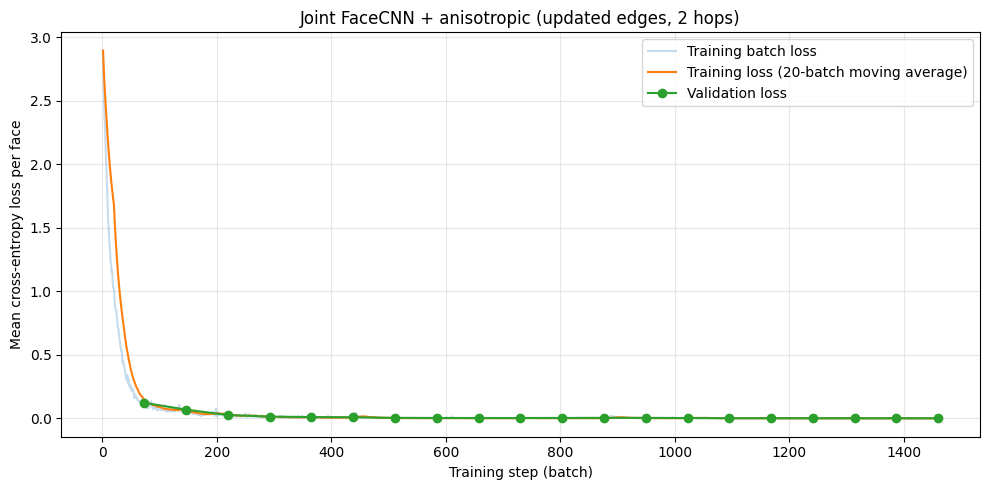

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

batch_log = pd.DataFrame(batch_history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(batch_log["step"], batch_log["loss"], alpha=0.25, label="Training batch loss")
ax.plot(batch_log["step"], batch_log["loss"].rolling(20, min_periods=1).mean(),
        label="Training loss (20-batch moving average)")
ax.plot([row["step"] for row in history],
        [row["validation_loss"] for row in history], marker="o", label="Validation loss")
ax.set_xlabel("Training step (batch)")
ax.set_ylabel("Mean cross-entropy loss per face")
ax.set_title(f"{training_mode.capitalize()} FaceCNN + anisotropic ({edge_mode} edges, 2 hops)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(run_dir / "loss.png", dpi=150)
plt.show()

## Accuracy and IoU: baseline + anisotropic variants

Read final cached training/validation predictions for the baseline and completed anisotropic runs only. Show checkpoint epoch, loss, accuracy, unweighted mean IoU (including stock), and per-class IoU. Missing runs are skipped. No inference or training.

In [16]:
# Compare cached final predictions across all completed variants.
from pathlib import Path
import json
import pandas as pd
import torch
from IPython.display import display
from uvnet_project.load_mfcad import DATA_DIR

project_dir = DATA_DIR.parent.parent
import re
variant_dirs = {"Geometry only": project_dir / "results/baseline_run_01"}
for folder in sorted((project_dir / "results").glob("anisotropic_*_run_*")):
    match = re.fullmatch(r"anisotropic_(static|updated)_(frozen|joint)_run_(\d+)", folder.name)
    if match:
        edges, mode, run_id = match.groups()
        label = f"{mode.capitalize()} FaceCNN + anisotropic ({edges} edges, run {run_id})"
        variant_dirs[label] = folder
class_names = {}
for label_file in (DATA_DIR / "labels").glob("*.json"):
    with label_file.open() as file:
        faces = json.load(file)["body"]["faces"]
    for face in faces:
        segment = face["segment"]
        class_names[segment["index"]] = segment["name"]
    if len(class_names) == 16:
        break

summary_rows, class_rows = [], []
for variant, directory in variant_dirs.items():
    # Final predictions are written only after training. Use the highest epoch
    # with both splits available, not a partially written final evaluation.
    completed = [folder for folder in directory.glob("epoch_*")
                 if folder.name.removeprefix("epoch_").isdigit()
                 and all((folder / f"{split}_predictions.pt").is_file()
                         for split in ("train", "validation"))]
    if not completed:
        print(f"No completed prediction files yet: {variant}")
        continue
    checkpoint_dir = max(completed, key=lambda folder: int(folder.name.split("_")[-1]))
    epoch = int(checkpoint_dir.name.split("_")[-1])
    for split in ("train", "validation"):
        results = torch.load(checkpoint_dir / f"{split}_predictions.pt",
                             map_location="cpu", weights_only=True)
        labels, predictions = results["labels"].long(), results["predictions"].long()
        num_classes = results["probabilities"].shape[1]
        confusion = torch.bincount(labels * num_classes + predictions,
                                  minlength=num_classes**2).reshape(num_classes, num_classes)
        intersection = confusion.diag()
        support = confusion.sum(1)
        union = support + confusion.sum(0) - intersection
        iou = intersection.double() / union.double().masked_fill(union == 0, float("nan"))
        per_class_accuracy = intersection.double() / support.double().masked_fill(support == 0, float("nan"))
        summary_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                 faces=labels.numel(), loss=results["loss"],
                                 accuracy=intersection.sum().item() / labels.numel(),
                                 mean_iou=iou.nanmean().item()))
        for index in range(num_classes):
            class_rows.append(dict(variant=variant, epoch=epoch, split=split,
                                   class_index=index, class_name=class_names.get(index, str(index)),
                                   support=support[index].item(), iou=iou[index].item(),
                                   accuracy=per_class_accuracy[index].item()))

if summary_rows:
    summary = pd.DataFrame(summary_rows).set_index(["variant", "epoch", "split"])
    per_class_metrics = pd.DataFrame(class_rows)
    display(summary.style.format({"loss": "{:.4f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}"}))
    print("Per-class IoU (unweighted class mean above, including stock):")
    display(per_class_metrics.pivot(index=["class_index", "class_name"],
                                    columns=["variant", "split"], values="iou").style.format("{:.2%}"))
    summary.to_csv(project_dir / "results/anisotropic_variant_metrics.csv")
    per_class_metrics.to_csv(project_dir / "results/anisotropic_variant_per_class_metrics.csv", index=False)
else:
    print("Run training through final prediction export before comparing metrics.")

Per-class IoU (unweighted class mean above, including stock):


## Loss comparison: baseline + anisotropic variants

Read saved training/validation histories for baseline and static/updated edge variants only. Frozen/joint FaceCNN modes remain separate. No training or inference in comparison cells.

Saved comparison: /home/yongjun23/project/results/anisotropic_variants_loss.png


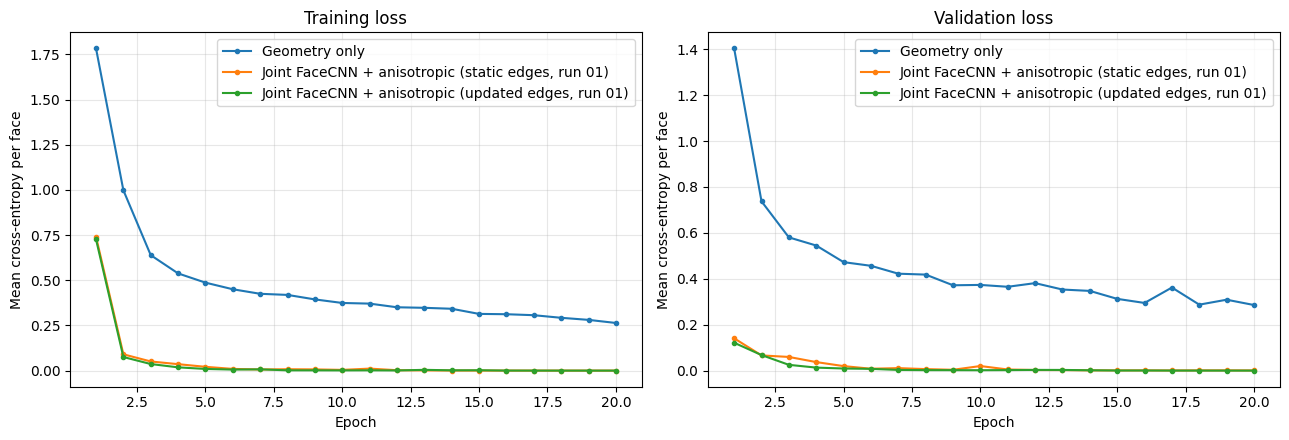

In [17]:
# Comparison from saved histories; no inference or training.
import matplotlib.pyplot as plt
import pandas as pd

import re
variants = {"Geometry only": project_dir / "results/baseline_run_01/history.csv"}
for folder in sorted((project_dir / "results").glob("anisotropic_*_run_*")):
    match = re.fullmatch(r"anisotropic_(static|updated)_(frozen|joint)_run_(\d+)", folder.name)
    if match:
        edges, mode, run_id = match.groups()
        label = f"{mode.capitalize()} FaceCNN + anisotropic ({edges} edges, run {run_id})"
        variants[label] = folder / "history.csv"
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plotted = 0
for label, path in variants.items():
    if not path.is_file():
        print(f"Not run yet: {label}")
        continue
    frame = pd.read_csv(path)
    if frame.empty:
        continue
    for ax, metric in zip(axes, ("train_loss", "validation_loss")):
        ax.plot(frame["epoch"], frame[metric], marker="o", markersize=3, label=label)
    plotted += 1
for ax, title in zip(axes, ("Training loss", "Validation loss")):
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean cross-entropy per face")
    ax.grid(alpha=0.3)
    if plotted:
        ax.legend()
fig.tight_layout()
if plotted:
    comparison_path = project_dir / "results/anisotropic_variants_loss.png"
    fig.savefig(comparison_path, dpi=150)
    print("Saved comparison:", comparison_path)
plt.show()